In [32]:
# Libraries and display settings
import pandas as pd
pd.set_option("display.float_format", "{:,.0f}".format)

### Part 1 – Load and Inspect the Datasets

In [33]:
# 1) Load the three datasets into separate DataFrames
exports = pd.read_csv("Coffee_export-1.csv")
imports = pd.read_csv("Coffee_import-1.csv")
production = pd.read_csv("Coffee_production-1.csv")

### Part 2-2 Data Quality Findings
#### 1. Missing values
- `.isnull().sum()` found **no missing values** in any of the three files (export, import, production).
- Export columns are `int64`. Production columns are `float64` even though there are no NaN, so the production figures include decimal values.
- **Hidden missing data:** A value of 0 can mean "no trade" or "not reported". For example, the import file has a combined `Belgium/Luxembourg` row as well as separate `Belgium` and `Luxembourg` rows, so some years are recorded as 0 in one of them. This is investigated in Part 3-3.
- **Placeholder values:** Brazil's export for 2014, 2015, and 2019 is −2,147,483,648, an impossible negative volume that represents missing data. Found during cleaning and fixed in Part 3-3.

#### 2. Numbers stored as text
- The only text columns are `Country` in all three files and `Coffee type` in production. Every year and total column is already numeric, so **no comma- or space-formatted numbers** were found.
- No column names have leading or trailing spaces.
- I still apply `pd.to_numeric()` to the numeric columns in Part 3 as a safety step, so the pipeline also works on a messier version of the data.
- Production uses crop-year headers (`1990/91` … `2019/20`), while export and import use calendar years (`1990` … `2019`). Year columns therefore can't be matched by name across files without renaming.

#### 3. Country name discrepancies
- **Leading whitespace:** 28 of the 35 import countries start with three spaces (e.g. `'   Austria'`). Export and production have none. Without stripping, `'   Austria'` and `'Austria'` would be treated as different countries.
- **Production vs. export:** The two files contain exactly the same 55 country names, so no renaming is needed between them.
- **Export vs. import:** 0 countries appear in both files. Export lists producing countries and import lists consuming countries, so an inner merge on `Country` would return an empty table. Request 4 (total trade volume) needs an outer merge.
- **Official UN names:** Names use formal UN style (`Viet Nam`, `Bolivia (Plurinational State of)`, `United States of America`). They already match across these files but would need mapping if combined with outside data.

### Part 3 – Clean the Datasets

#### Part 3–1 Column cleanup

In [34]:
# Save the original names so we can show before/after
before = {"Export": exports.columns.tolist(),
          "Import": imports.columns.tolist(),
          "Production": production.columns.tolist()}

# 1) Strip spaces from every column name (safety step, even though none were found)
for df in [exports, imports, production]:
    df.columns = df.columns.str.strip()

# 2) Production crop years '1990/91' -> calendar year '1990'
production.columns = [col[:4] if "/" in col else col for col in production.columns]

# 3) Rename text and total columns to one lowercase style
rename_map = {
    "Country": "country",
    "Coffee type": "coffee_type",
    "Total_export": "total_export",
    "Total_import": "total_import",
    "Total_production": "total_production",
}
exports = exports.rename(columns=rename_map)
imports = imports.rename(columns=rename_map)
production = production.rename(columns=rename_map)

In [35]:
# Check: show the first 3 and last 2 column names, before and after
after = {"Export": exports.columns.tolist(),
         "Import": imports.columns.tolist(),
         "Production": production.columns.tolist()}

for name in after:
    print(f"=== {name} ===")
    print("Before:", before[name][:3], "...", before[name][-2:])
    print("After: ", after[name][:3], "...", after[name][-2:])
    print()

# All three files now share the same year columns?
year_cols = [c for c in exports.columns if c.isdigit()]
print("Same years in all files:",
      all(c in imports.columns and c in production.columns for c in year_cols))

=== Export ===
Before: ['Country', '1990', '1991'] ... ['2019', 'Total_export']
After:  ['country', '1990', '1991'] ... ['2019', 'total_export']

=== Import ===
Before: ['Country', '1990', '1991'] ... ['2019', 'Total_import']
After:  ['country', '1990', '1991'] ... ['2019', 'total_import']

=== Production ===
Before: ['Country', 'Coffee type', '1990/91'] ... ['2019/20', 'Total_production']
After:  ['country', 'coffee_type', '1990'] ... ['2019', 'total_production']

Same years in all files: True


- **Stripped whitespace** from all column names as a safety step (none was found in Part 2).
- **Unified naming style:** renamed `Country`, `Coffee type`, and the three `Total_*` columns to lowercase snake_case (`country`, `coffee_type`, `total_export`, ...). One consistent style makes later code easier to read and avoids case-sensitive `KeyError`s.
- **Aligned year columns:** production used crop years (`1990/91`), while export and import used calendar years (`1990`). I kept the first four characters so all three files share the same year labels (`1990` … `2019`). Trade-off: a crop year runs from one autumn to the next summer, so this is a simplification, but it makes year-by-year comparison across files possible.

### Part 3-2 Convert number columns stored as text into real numbers

In [36]:
# 1) Find the number columns without typing 30 names
def get_number_cols(df):
    # year columns are all digits ('1990'); total columns start with 'total'
    return [c for c in df.columns if c.isdigit() or c.startswith("total")]

# 2) Cleaning steps: text -> remove commas and spaces -> number
def to_number(series):
    text = series.astype(str)                        # treat every value as text
    text = text.str.replace(",", "", regex=False)    # '1,234'  -> '1234'
    text = text.str.strip()                          # ' 1234 ' -> '1234'
    return pd.to_numeric(text, errors="coerce")      # '1234' -> 1234, unreadable -> NaN

print("Export number columns:", len(get_number_cols(exports)))
print("Import number columns:", len(get_number_cols(imports)))
print("Production number columns:", len(get_number_cols(production)))

Export number columns: 31
Import number columns: 31
Production number columns: 31


In [37]:
# Demo on one column: show the type before and after conversion
as_text = exports["1990"].astype(str)
print("Before:", as_text.dtype, as_text.head(3).tolist())

as_number = to_number(as_text)
print("After: ", as_number.dtype, as_number.head(3).tolist())

Before: str ['5040000', '9360000', '1016160000']
After:  int64 [5040000, 9360000, 1016160000]


In [38]:
# Apply the conversion to every number column in all three files
frames = {"Export": exports, "Import": imports, "Production": production}

for name, df in frames.items():
    for col in get_number_cols(df):
        df[col] = to_number(df[col])

# Check: every number column is numeric, and no new NaN was created
for name, df in frames.items():
    cols = get_number_cols(df)
    all_numeric = all(pd.api.types.is_numeric_dtype(df[c]) for c in cols)
    print(f"{name}: all numeric = {all_numeric}, "
          f"dtypes = {df[cols].dtypes.unique().tolist()}, "
          f"NaN = {df[cols].isnull().sum().sum()}")

Export: all numeric = True, dtypes = [dtype('int64')], NaN = 0
Import: all numeric = True, dtypes = [dtype('int64')], NaN = 0
Production: all numeric = True, dtypes = [dtype('float64')], NaN = 0


- **Finding the columns:** instead of typing 31 names, I select columns whose name is all digits (years) or starts with `total`.
- **Conversion steps:** each column is treated as text, commas and spaces are removed, and `pd.to_numeric(errors="coerce")` converts it to a number. Any value that still can't be read becomes NaN instead of crashing the pipeline.
- **Result:** the raw files were already numeric, so the values did not change. Running the conversion anyway makes the pipeline safe for messier versions of the data (e.g. `"1,234 "`). The demo cell shows one column going from `str` to `int64`.
- **Check:** all number columns are numeric and no new NaN was created by the conversion.

### Part 3-3 Identify missing data

In [39]:
# Count NaN and zeros in each file
for name, df in frames.items():
    cols = get_number_cols(df)
    nan_count = df[cols].isnull().sum().sum()           # real NaN
    zero_count = (df[cols] == 0).sum().sum()            # zeros (possible hidden missing)
    all_zero_rows = df.loc[df[cols[-1]] == 0, "country"].tolist()   # total = 0
    print(f"{name}: NaN = {nan_count}, zeros = {zero_count}, "
          f"countries with total 0 = {all_zero_rows}")

Export: NaN = 0, zeros = 117, countries with total 0 = []
Import: NaN = 0, zeros = 54, countries with total 0 = []
Production: NaN = 0, zeros = 77, countries with total 0 = []


In [40]:
# Do the combined and separate rows report the same years? (risk of double-counting)
year_cols = [c for c in imports.columns if c.isdigit()]
bl = imports[imports["country"].str.strip().isin(["Belgium", "Luxembourg", "Belgium/Luxembourg"])]

for _, row in bl.iterrows():
    years = [c for c in year_cols if row[c] > 0]
    span = f"{years[0]}–{years[-1]}" if years else "no data"
    print(f"{row['country'].strip():<20} reports in: {span}")

Belgium              reports in: 1999–2019
Belgium/Luxembourg   reports in: 1990–1998
Luxembourg           reports in: 1999–2019


In [41]:
# Hidden missing values: negative volumes are impossible
for name, df in {"Export": exports, "Import": imports, "Production": production}.items():
    year_cols = [c for c in df.columns if c.isdigit()]
    neg = df[year_cols] < 0
    for idx in df.index[neg.any(axis=1)]:
        bad_years = [y for y in year_cols if neg.loc[idx, y]]
        print(f"{name}: {df.loc[idx, 'country']} -> {bad_years}, value = {df.loc[idx, bad_years[0]]:,}")

Export: Brazil -> ['2014', '2015', '2019'], value = -2,147,483,648


In [42]:
# Replace impossible negative values with NaN, then fill them from neighbouring years
for df, total in [(exports, "total_export"), (imports, "total_import"), (production, "total_production")]:
    year_cols = [c for c in df.columns if c.isdigit()]
    df[year_cols] = df[year_cols].astype(float)
    df[year_cols] = df[year_cols].mask(df[year_cols] < 0)           # negative -> NaN
    df[year_cols] = df[year_cols].interpolate(axis=1, limit_direction="both")
    df[total] = df[year_cols].sum(axis=1)                           # recompute total from clean years

print("Brazil 2013–2019 (bn kg):")
print((exports.loc[exports["country"] == "Brazil", [str(y) for y in range(2013, 2020)]] / 1e9).round(2))

Brazil 2013–2019 (bn kg):
   2013  2014  2015  2016  2017  2018  2019
2     2     2     2     2     2     2     2


In [43]:
# Handling: keep zeros as real values; fill any NaN with 0 as a safety step
for name, df in frames.items():
    cols = get_number_cols(df)
    df[cols] = df[cols].fillna(0)

# Check: no NaN left
for name, df in frames.items():
    cols = get_number_cols(df)
    print(f"{name}: NaN left = {df[cols].isnull().sum().sum()}")

Export: NaN left = 0
Import: NaN left = 0
Production: NaN left = 0


- **Identification:** `.isnull().sum()` found no NaN in any file, including after the `to_numeric` conversion. I also counted zeros, because a 0 could be either "no trade" or "not reported".
- **Decision: keep zeros and fill any NaN with 0.** These are official trade and production records, so a 0 most likely means no recorded trade or output that year. The `fillna(0)` is a safety step for future data.
- **Why not drop rows?** Dropping would remove whole countries and their other 29 years of real data. It would also bias totals toward large producers, because small countries are the ones most likely to have zero years.
- **Why not fill with the mean or median?** That would invent coffee volumes that were never recorded and inflate the global totals. The median is safer than the mean here (a few huge countries like Brazil skew the mean), but both still create data.
- **Belgium/Luxembourg:** The combined row reports only in 1990–1998, and the separate `Belgium` and `Luxembourg` rows report only in 1999–2019. The periods don't overlap, so this is a change in reporting, not double-counting. 39 of the 54 zeros in the import file come from these three rows ("reported elsewhere", not "no trade"). Global totals are correct, but any single one of these rows on its own has an incomplete time series.

- **Hidden missing values found in the chart:** global exports appeared to halve in 2014–2015 and 2019 while imports kept rising. Tracing the drop showed **Brazil's exports recorded as exactly −2,147,483,648** in 2014, 2015, and 2019. This is the minimum 32-bit integer, a common placeholder for missing data, and a negative volume is impossible. It was the only negative value in all three files. `.isnull()` cannot detect it because the cell holds a number.
- **Handling: replaced negatives with NaN and interpolated across years.** Brazil is the largest exporter, so leaving the values would make world exports look like they halved, and filling with 0 would erase a full year of its trade. Linear interpolation uses Brazil's own neighbouring years, which keeps the trend realistic. Trade-off: the filled values are estimates, not reported figures, and 2019 (the last year) can only copy 2018. Totals were recomputed from the cleaned year columns.

### Part 3-4 Standardize country names

In [44]:
# Save totals before cleaning so we can check nothing was lost
import_total_before = imports["total_import"].sum()
import_rows_before = len(imports)

# 1) Strip leading/trailing spaces from text values in all three files
exports["country"] = exports["country"].str.strip()
imports["country"] = imports["country"].str.strip()
production["country"] = production["country"].str.strip()
production["coffee_type"] = production["coffee_type"].str.strip()

# 2) One mapping, applied to all three files
#    Belgium and Luxembourg were reported together until 1998 and separately from 1999
country_map = {
    "Belgium": "Belgium/Luxembourg",
    "Luxembourg": "Belgium/Luxembourg",
}
exports["country"] = exports["country"].replace(country_map)
imports["country"] = imports["country"].replace(country_map)
production["country"] = production["country"].replace(country_map)

# 3) Combine rows that now share the same name (adds the three Belgium/Luxembourg rows together)
imports = imports.groupby("country", as_index=False).sum()

In [45]:
# Check 1: no country names with extra spaces left
for name, df in {"Export": exports, "Import": imports, "Production": production}.items():
    spaced = [c for c in df["country"] if c != c.strip()]
    print(f"{name}: {len(spaced)} names with extra spaces")

# Check 2: Belgium/Luxembourg is now one row with no gap years
bl = imports[imports["country"] == "Belgium/Luxembourg"]
year_cols = [c for c in imports.columns if c.isdigit()]
print("\nBelgium/Luxembourg rows:", len(bl))
print("Zero years:", (bl[year_cols] == 0).sum().sum())

# Check 3: rows went from 35 to 33, but the total import volume did not change
print(f"\nImport rows: {import_rows_before} -> {len(imports)}")
print("Total import unchanged:", import_total_before == imports["total_import"].sum())

# Check 4: production and export still have exactly the same countries
print("Production = Export countries:", set(production["country"]) == set(exports["country"]))

Export: 0 names with extra spaces
Import: 0 names with extra spaces
Production: 0 names with extra spaces

Belgium/Luxembourg rows: 1
Zero years: 0

Import rows: 35 -> 33
Total import unchanged: True
Production = Export countries: True


- **Whitespace:** stripped leading/trailing spaces from `country` in all three files (28 import names had three leading spaces) and from `coffee_type`.
- **One mapping for all files:** the same `country_map` dictionary is applied to export, import, and production, so a name can never be fixed in one file and missed in another.
- **Belgium/Luxembourg:** the import file reported them as one row in 1990–1998 and as two rows from 1999. I mapped `Belgium` and `Luxembourg` to `Belgium/Luxembourg` and summed the rows with `groupby`. This gives one continuous 1990–2019 series. Import rows went from 35 to 33 and total import volume is unchanged.
- **Production vs. export:** names already matched exactly (55 countries), so no other renaming was needed. Export and import still share no countries, which is expected (producers vs. consumers) and handled with an outer merge in Request 4.

# Part 3-5 Data Integrity Check: Duplicates and Outliers

In [63]:
# Check duplicates in each cleaned file
files = {"Export": exports, "Import": imports, "Production": production}

for name, df in files.items():
    # 1) Exact duplicates: rows that are identical in every column
    exact = df.duplicated().sum()

    # 2) Key duplicates: the same country appearing more than once in one file
    key_dupes = df.duplicated(subset=["country"]).sum()

    print(f"{name}: exact duplicates = {exact}, duplicate countries = {key_dupes}")

Export: exact duplicates = 0, duplicate countries = 0
Import: exact duplicates = 0, duplicate countries = 0
Production: exact duplicates = 0, duplicate countries = 0


In [64]:
# Check for impossible or suspicious values
for name, df in files.items():
    year_cols = [c for c in df.columns if c.isdigit()]

    negatives = (df[year_cols] < 0).sum().sum()                 # volumes can't be negative
    sentinel  = (df[year_cols] == -2147483648).sum().sum()      # the int32 placeholder

    # Largest single-year value, to confirm it belongs to a real major country
    max_val = df[year_cols].max().max()
    max_country = df.loc[df[year_cols].max(axis=1).idxmax(), "country"]

    print(f"{name}: negatives = {negatives}, placeholder = {sentinel}, "
          f"largest value = {max_val:,.0f} ({max_country})")

Export: negatives = 0, placeholder = 0, largest value = 2,138,220,000 (Brazil)
Import: negatives = 0, placeholder = 0, largest value = 1,851,240,000 (United States of America)
Production: negatives = 0, placeholder = 0, largest value = 3,907,860,000 (Brazil)


- **What counts as a duplicate:** each file should have one row per country, so I defined a duplicate as (1) a row identical in every column, or (2) the same country name appearing more than once in the same file, checked after stripping spaces from names.
- **Result:** 0 exact duplicates and 0 duplicate countries in all three files.
- **Near-duplicate handled earlier:** Belgium, Luxembourg, and Belgium/Luxembourg were the same trade area reported in different periods. I combined them into one row in Part 3-4, so the total import volume stayed the same and nothing was counted twice.
- **Outliers:** after cleaning, there are 0 negative values and 0 placeholder values (−2,147,483,648) in all three files. The largest single-year values belong to the countries we expect: Brazil for exports (about 2.1 billion) and production (about 3.9 billion), and the United States for imports (about 1.9 billion). These are real values from the largest producer and the largest consumer, not errors.

# Business Requests

In [48]:
# Data check: year columns, leftover negative values, coffee type column
print(exports.columns.tolist())
print("Negative values left:", (exports.select_dtypes("number") < 0).sum().sum())
print(production.columns.tolist())

['country', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', 'total_export']
Negative values left: 0
['country', 'coffee_type', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', 'total_production']


## 1. Identifying the Largest Coffee Exporter (1990–1994)

#### 1-1 Analysis Code

In [49]:
# Request 1: Which country exported the most coffee from 1990 to 1994?
req1 = exports.copy()

# All rows (:), only the 1990–1994 year columns, added across each row (axis=1)
req1["total_1990_1994"] = req1.loc[:, "1990":"1994"].sum(axis=1)

# Country with the largest total
top = req1.loc[req1["total_1990_1994"].idxmax(), ["country", "total_1990_1994"]]
print(f"Largest exporter: {top['country']} ({top['total_1990_1994']:,.0f})")

Largest exporter: Brazil (5,521,260,000)


#### 1-2 Output Table

In [50]:
# Top 5 exporters for context
top5 = (req1.nlargest(5, "total_1990_1994")[["country", "total_1990_1994"]]
            .reset_index(drop=True))
top5.index = top5.index + 1   # rank starts at 1
top5

,country,total_1990_1994
1,Brazil,"5,521,260,000"
2,Colombia,"4,106,580,000"
3,Indonesia,"1,676,700,000"
4,Côte d'Ivoire,"1,146,660,000"
5,Mexico,"995,940,000"


#### 1-3 Visualization

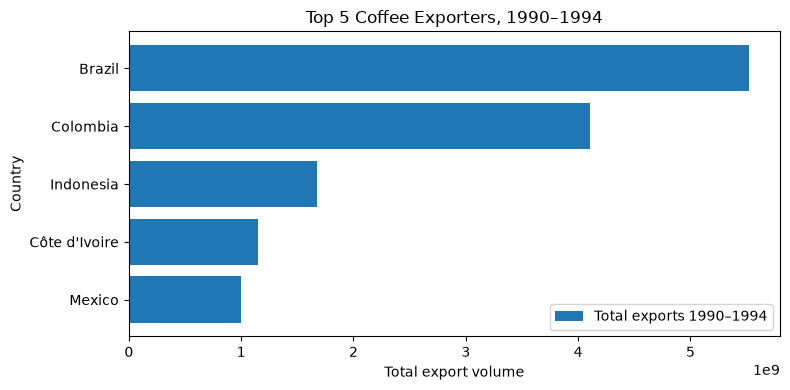

In [51]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top5["country"], top5["total_1990_1994"], label="Total exports 1990–1994")
ax.invert_yaxis()   # largest on top
ax.set_title("Top 5 Coffee Exporters, 1990–1994")
ax.set_xlabel("Total export volume")
ax.set_ylabel("Country")
ax.legend()
plt.tight_layout()
plt.show()

#### 1-4 Stakeholder Summary: 
- **Brazil was the world's largest coffee exporter from 1990 to 1994**, shipping about 5.5 billion units, roughly 34% more than **second-place Colombia.**
- Together, **these two countries made up about 72%** of the top five exporters' volume.
- We recommend treating Brazil and Colombia as core sourcing partners, while building relationships with secondary exporters such as Indonesia and Mexico **to reduce the risk of a supply shock** in either country.
#### 1-5 Data Limitations:
- The dataset does not state its **units**, so these figures are best used **to compare countries** rather than as exact tonnage.
- This is early-1990s data and **may not reflect today's market.**

## 2. Top Five Coffee Producers (1999-2004)

#### 2-1 Analysis Code

In [52]:
# Request 2: Top 5 countries by total coffee production, 1999–2004
req2 = production.copy()

# All rows (:), only the 1999–2004 year columns, added across each row (axis=1)
req2["total_1999_2004"] = req2.loc[:, "1999":"2004"].sum(axis=1)

# One total per country (in case a country appears in more than one row)
req2_country = req2.groupby("country", as_index=False)["total_1999_2004"].sum()

#### 2-2 Output Table

In [53]:
# Top 5 producers, ranked 1–5 (keep="all" keeps ties at 5th place)
top5_prod = (req2_country.nlargest(5, "total_1999_2004", keep="all")
                         .reset_index(drop=True))
top5_prod.insert(0, "rank", top5_prod.index + 1)   # rank starts at 1
top5_prod

,rank,country,total_1999_2004
0,1,Brazil,"13,605,540,000"
1,2,Viet Nam,"4,850,760,000"
2,3,Colombia,"3,970,500,000"
3,4,Indonesia,"2,462,880,000"
4,5,India,"1,715,040,000"


#### 2-3 Visualization

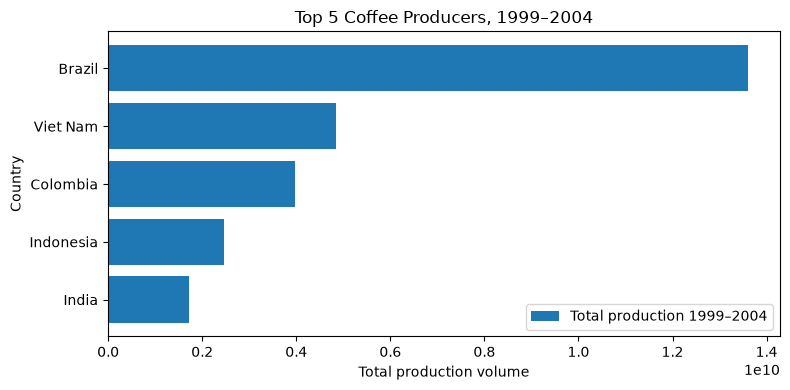

In [54]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top5_prod["country"], top5_prod["total_1999_2004"], label="Total production 1999–2004")
ax.invert_yaxis()   # largest on top
ax.set_title("Top 5 Coffee Producers, 1999–2004")
ax.set_xlabel("Total production volume")
ax.set_ylabel("Country")
ax.legend()
plt.tight_layout()
plt.show()

#### 2-4 Stakeholder Summary:
- From 1999 to 2004, Brazil was by far the largest coffee producer, with about 13.6 billion units, roughly 2.8 times more than second-place Viet Nam and about 51% of the top five's combined output. Viet Nam, Colombia, Indonesia, and India complete the top five, giving us large-scale producers across three regions: South America, Southeast Asia, and South Asia. To diversify suppliers while keeping supply stable, we recommend keeping Brazil as our anchor supplier and spreading long-term contracts across Viet Nam, Colombia, and Indonesia, so a poor harvest in one country does not disrupt our supply.
#### 2-5 Data Limitations:
- Production does not equal exports. Some producers, such as Brazil and India, consume part of their own coffee.
- A six-year total shows size, not stability. A country with one very large year could rank high even if its production swings a lot.
- The dataset does not state its units, so these figures are best used to compare countries.

## 3. High-Potential "Hidden Gem" Producers

In [55]:
# How many distinct coffee types, and how many countries in each?
production["coffee_type"].value_counts()

coffee_type
Arabica            22
Robusta            15
Robusta/Arabica    10
Arabica/Robusta     8
Name: count, dtype: int64

#### 3-1 Analysis Code

In [56]:
# Request 3: second-highest producer for each coffee type, 1990–1994
req3 = production.copy()

# All rows, only the 1990–1994 columns, added across each row
req3["total_1990_1994"] = req3.loc[:, "1990":"1994"].sum(axis=1)

# Rank countries inside each coffee type
# dense = tied values share a rank and no rank number is skipped (1, 2, 2, 3)
req3["rank"] = (req3.groupby("coffee_type")["total_1990_1994"]
                    .rank(method="dense", ascending=False))

#### 3-2 Output Table

In [57]:
# Keep only 2nd place (ties at 2nd place stay in)
second_place = (req3[req3["rank"] == 2][["coffee_type", "country", "total_1990_1994"]]
                    .sort_values("total_1990_1994", ascending=False)
                    .reset_index(drop=True))
second_place

,coffee_type,country,total_1990_1994
0,Arabica/Robusta,Mexico,"1,319,040,000"
1,Robusta/Arabica,India,"911,220,000"
2,Arabica,Ethiopia,"803,340,000"
3,Robusta,Madagascar,"247,200,000"


#### 3-3 Visualization

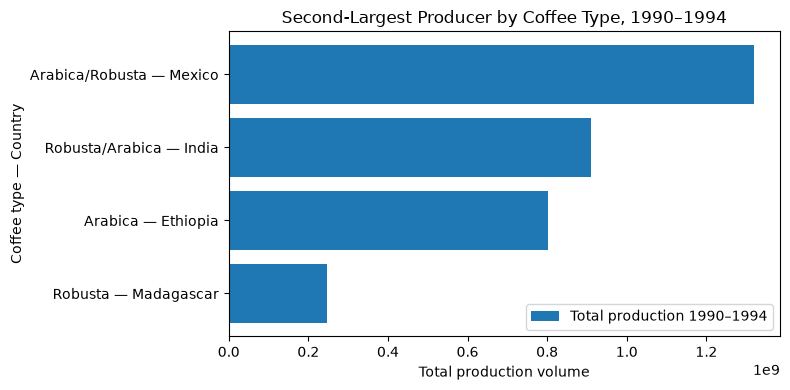

In [58]:
import matplotlib.pyplot as plt

labels = second_place["coffee_type"] + " — " + second_place["country"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(labels, second_place["total_1990_1994"], label="Total production 1990–1994")
ax.invert_yaxis()
ax.set_title("Second-Largest Producer by Coffee Type, 1990–1994")
ax.set_xlabel("Total production volume")
ax.set_ylabel("Coffee type — Country")
ax.legend()
plt.tight_layout()
plt.show()

#### 3-4 Stakeholder Summary:
- Looking beyond the market leaders, the strongest second-tier producer for each of the four coffee types from 1990 to 1994 was Mexico for mainly-Arabica blends (about 1.3 billion units), India for mainly-Robusta blends (about 0.9 billion), Ethiopia for Arabica (about 0.8 billion), and Madagascar for Robusta (about 0.25 billion). These countries already produce at scale but receive less attention than the market leaders, which may give us better access, pricing, and a backup if a leading supplier has a poor harvest. We recommend starting pilot sourcing partnerships with Mexico, India, and Ethiopia, and evaluating Madagascar as a smaller Robusta backup.
#### 3-5 Data Limitations:
- I used dense ranking so that countries tied for second place would all be listed. No ties occurred in this period.
- "Arabica/Robusta" and "Robusta/Arabica" appear to show the main type first (e.g., Brazil and Mexico are mostly Arabica; Indonesia and Viet Nam are mostly Robusta), so I kept them as separate groups. The data does not split their volume by bean type.
- "Second place" depends on how many countries are in each group. Madagascar ranks second in Robusta, but its volume is much smaller than the other second-place countries.
- This is 1990–1994 data, so current production levels may be different.

## 4. Global Coffee Trade Footprints

In [59]:
print(imports.columns.tolist())

['country', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', 'total_import']


#### 4-1 Analysis Code

In [60]:
# Request 4: total exports + total imports per country across the whole timespan
exp_tot = exports[["country", "total_export"]]
imp_tot = imports[["country", "total_import"]]   # ← change if your column name is different

# outer: keep countries that appear in only one file
# fillna(0): a country missing from one file has 0 in that direction
trade = exp_tot.merge(imp_tot, on="country", how="outer").fillna(0)

# Total Trade Volume = Imports + Exports
trade["total_trade_volume"] = trade["total_export"] + trade["total_import"]

print("Countries after merge:", len(trade))

Countries after merge: 88


#### 4-2 Output Table

In [61]:
top5_trade = (trade.nlargest(5, "total_trade_volume")
                   .reset_index(drop=True))
top5_trade.index = top5_trade.index + 1   # rank starts at 1
top5_trade

,country,total_export,total_import,total_trade_volume
1,Brazil,"46,343,580,000",0,"46,343,580,000"
2,United States of America,0,"42,507,660,000","42,507,660,000"
3,Germany,0,"31,481,400,000","31,481,400,000"
4,Viet Nam,"24,924,480,000",0,"24,924,480,000"
5,Colombia,"19,878,480,000",0,"19,878,480,000"


#### 4-3 Visualization

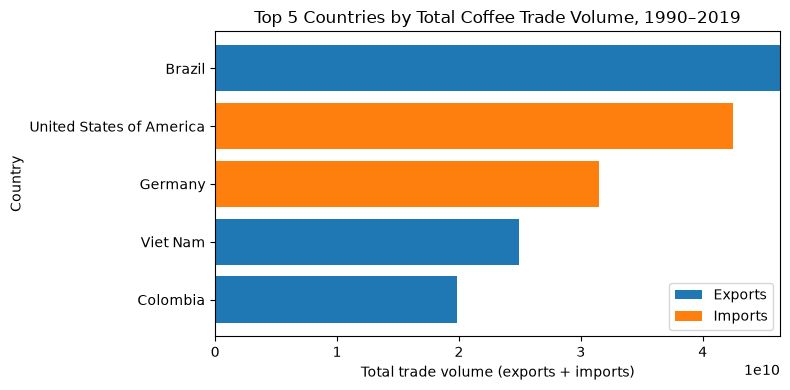

In [62]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top5_trade["country"], top5_trade["total_export"], label="Exports")
ax.barh(top5_trade["country"], top5_trade["total_import"],
        left=top5_trade["total_export"], label="Imports")
ax.invert_yaxis()
ax.set_title("Top 5 Countries by Total Coffee Trade Volume, 1990–2019")
ax.set_xlabel("Total trade volume (exports + imports)")
ax.set_ylabel("Country")
ax.legend()
plt.tight_layout()
plt.show()

#### 4-4 Stakeholder Summary:
- From 1990 to 2019, the five countries that moved the most coffee were Brazil, the United States, Germany, Viet Nam, and Colombia. They fall into two clear groups: Brazil, Viet Nam, and Colombia are major producers that only export, while the United States and Germany are major consumer markets that only import, with U.S. imports nearly matching Brazil's total exports. We recommend securing long-term supply contracts with the three producing countries and focusing our distribution and sales strategy on the U.S. and German markets, where the largest share of coffee is bought.
#### 4-5 Data Limitations:
- I used an outer merge and filled missing values with 0, which assumes a country with no record in one file had no trade in that direction. In this data, exporters and importers do not overlap at all, so an inner merge would have returned an empty table.
- Some importers, such as Germany, roast and re-export coffee to other countries. Their import totals may include coffee that is later sold elsewhere, so some volume may be counted more than once.
- The totals cover all 30 years, so they show long-term scale but hide recent changes, such as Viet Nam's fast growth.
- The dataset does not state its units, so these figures are best used to compare countries.

## 5. Sourcing Traceability Analysis

### 5-1 Executive Summary
Our current data cannot map which exporting countries supply each importing country. Each of the three files records one total per country per year (how much it produced, exported, or imported), but none of them record where a shipment came from or where it went. Without that link, we cannot connect Brazil's exports to, for example, the United States' imports.

**What is missing:** a link between each exporter and each importer.

**Why the analysis cannot be done:** the export and import files list different countries (producers vs. consumers) with only yearly totals, so there is no shared record of a trade between two specific countries.

**What we would need:** a transaction-level trade table with one row per trade flow, containing:
- **Origin country** (exporter)
- **Destination country** (importer)
- **Year**
- **Volume**
- Ideally, **coffee type** and **price**

With this table, we could build a full supply network map, such as Brazil → United States → volume per year.

### 5-2 Data Limitations
- All three files are aggregated at the country level, so trade routes cannot be rebuilt from them.
- The export and import files mostly cover different countries, as Request 4 showed: every top-five country was either only an exporter or only an importer.